In [1]:
#!pip install -Uq astroquery

<p>

<h1><b><center></center></b></h1>
<h1><b><center>Minería de Datos</center></b></h1>
<h2><b><center>Tercer proyecto computacional</center></b><h2>
<h3><b><center>Edad cinemática de poblaciones estelares de la Vía Láctea</center></b><h3>

</p>

<hr/>
<b>Nombre</b>: Gabriel Rodríguez Suárez
<br/>
<b>Cédula</b>: 1089931997
<hr/>
<b>Estado</b>: En proceso.
<br/>
<b>Última actualización</b>: 11-11-2026
<br/>
<b>Tiempo de ejecucción</b>:

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
# Módulos de librerías
import astropy.units as u
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.figure_factory as ff
# Rutinas específicas
from astropy.coordinates import SkyCoord, CartesianRepresentation
from astropy.table import Table
from astroquery.gaia import Gaia
from astroquery.simbad import Simbad

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


Para estre proyecto debemos consultar los datos de tres poblaciones estelares cercanas al Sistema Solar.

Los cúmulos abiertos de estrellas son agrupaciones de éstas y generalmente contienen estrellas jóvenes que comparten un movimiento en el espacio similar. Visto desde La Tierra, las componentes del movimiento de sus miembros son similares, lo que indica que las estrellas van viajando juntas por la galaxia.

Las poblaciones estelares que abordaremos en este proyecto son:

- Upper Scorpius association.
- Lower Centaurus-Crux association.
-

Entonces lo primero que debemos hacer es un query de `astroquey.gaia`, ya que Gaia es la mission espacial de la ESA que registró por varios años los datos de movimiento propio y paralaje de cerca de 1000 millones de estrellas.

Vamos a determinar entonces las estrellas pertenecientes a estas asociaciones y estimar su edad cinemática y revisar que sea consistente el resultado obtenido con el de la literatura.

## **Lower Centaurus-Crux association**

El cúmulo abierto de Lower Centaurus-Crux está ubicado en las coordenadas ecuatoriales de ICRS:

$$\text{RA}:[12h,19min,00s]$$
$$\text{DEC}:[-57,06',00'']$$

Es una de las regiones de formación estelar de estrellas tipo O más cercanas al Sistema Solar, ubicado en las constelaciones de Lupus, Centauro y Crux.

Para el momento de desarrollar el proyecto SIMBAD estaba caído en sus servidores de `astroquery`, por lo que ingresamos a la base de datos y cargaremos entonces la VOTABLE que contiene los datos solicitados.

In [3]:
simbad_LCC = Table.read('simbad_LCC_votable.vot', format='votable')
#simbad2_LCC = Table.read('simbad (2)', format='votable')

Crearemos una nueva tabla sólo con los datos que realmene necesitamos para nuestro trabajo.

In [4]:
sub_LCC = simbad_LCC['RA_d', 'DEC_d', 'PLX_plx']

Para hacer el cross-match con los datos de Gaia, queremos identificar cuál es la estrella más cercana y la más lejana, para ello pasaremos por tres filtros los datos:

1. Que el paralaje no sea nulo ni negativo.
2. Que los movimientos propios no sean nulos o negativos.
3. Que el paralaje esté acotado entre una distancia de la estrella maś cercana a la Tierra y la más lejana registrada.

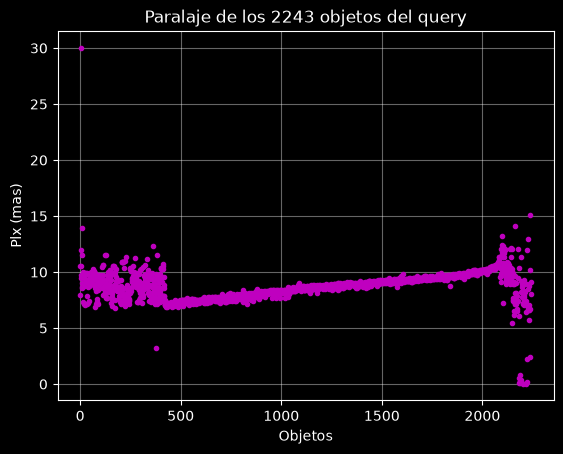

In [5]:
plt.style.use("dark_background")

plt.plot(sub_LCC['PLX_plx'], 'm.')
plt.title(f"Paralaje de los {len(sub_LCC)} objetos del query")
plt.xlabel('Objetos')
plt.ylabel('Plx (mas)')
plt.grid(alpha=0.4)
plt.show()

Definimos la máscara booleana y vamos a tomar entonces los paralajes mínimo y máximo de estos objetos.

In [6]:
sd_plx_LCC = sub_LCC['PLX_plx'].data
mask_plx_LCC = (sd_plx_LCC >= 5.0) & (sd_plx_LCC <= 15.0)

plxs_LCC = sd_plx_LCC[mask_plx_LCC]
print(f"Plx mínimo: {np.min(plxs_LCC)}")
print(f"Plx máximo: {np.max(plxs_LCC)}")

Plx mínimo: 5.411200046539307
Plx máximo: 14.096099853515625


Hacemos este primer query para poder filtrar los datos de Gaia con mayor facilidad. Primero debe tenerse en cuenta que el paralaje está limitado por la resolución de los telescopios, aquí en el gráfico anterior podemos ver que hay objetos con paralajes casi cero, lo que indica que son muy distantes. Por el contrario, aquellos con paralajes muy grandes son objetos más cercanos a La Tiera.

Lo que sí puede observarse es una tendencia bien definida de los datos de paralaje de SIMBAD de LCC association a estar en un rango entre 5 mas y 15 mas, por lo que nuestro query de Gaia será delimitado por estos valores de paralaje.

In [7]:
def sex2dec(d, arcmin, arcsec):
  if d < 0:
    decs = d - arcmin / 60 - arcsec / 3600
  else:
    decs = d + arcmin / 60 + arcsec / 3600
  return decs

Para hacer los queries en Gaia debemos definir las coordenadas centrales del cúmulo LCC.

In [ ]:
ra_LCC = sex2dec(12,19,0) * 15
print(f"RA: {ra_LCC}°")

dec_LCC = sex2dec(-57,6,0)
print(f"dec: {dec_LCC}°")

RA: 184.75°
dec: -57.1°


In [9]:
# Aquí hacemos el query al centro de LCC:
coords_LCC = SkyCoord(
    ra= ra_LCC,
    dec = dec_LCC,
    unit=(u.degree, u.degree),
    frame="icrs"
)

print("SkyCoord de LCC association:")
print(coords_LCC)

SkyCoord de LCC association:
<SkyCoord (ICRS): (ra, dec) in deg
    (184.75, -57.1)>


Ya habiendo definido las coordenadas del centro y teniendo las limitaciones que nos da el primer query de SIMBAD para LCC association, podemos hacer el query el cross-match con Gaia DR3.

In [ ]:
# query_LCC = f"""
# SELECT TOP 6000
# source_id,
# ra,
# dec,
# parallax,
# parallax_over_error AS plx_oerr,
# pmra,
# pmra_error,
# pmdec,
# pmdec_error,
# phot_g_mean_mag,
# radial_velocity,
# radial_velocity_error AS rv_error
# FROM gaiadr3.gaia_source
# WHERE CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra_LCC}, {dec_LCC}, 5.0)) = 1
# AND parallax >= 5 AND parallax <= 15
# AND pmra IS NOT NULL
# AND pmdec IS NOT NULL
# AND phot_g_mean_mag < 14.0
# AND radial_velocity IS NOT NULL
# """

# job_LCC = Gaia.launch_job(query_LCC)
# result_LCC = job_LCC.get_results()

In [151]:
result_LCC

source_id,ra,dec,parallax,plx_oerr,pmra,pmra_error,pmdec,pmdec_error,phot_g_mean_mag,radial_velocity,rv_error
,deg,deg,mas,,mas / yr,mas / yr,mas / yr,mas / yr,mag,km / s,km / s
int64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float32
6060249260392210944,192.74262865215735,-58.17691145027575,8.482504067796272,752.0335,0.919739568814625,0.008846368,2.6647006543768526,0.0108814305,12.251515,-8.573328,0.48801717
6061062697162344448,189.81585316330742,-57.323377148833416,7.5007442364353185,448.32678,14.858779423684172,0.012813976,15.228591800696343,0.018443096,8.6661215,40.903034,0.14031394
6061063693594763392,189.70679197751556,-57.29749632044603,10.368864426015934,660.99164,-18.99936466702944,0.012196881,-26.8813253154911,0.014769824,12.992582,-4.5599914,0.8271774
6061216560068545536,190.12451763416115,-56.85487646787703,5.673340128887866,398.3111,-34.02022553037643,0.01169233,-4.703313370014058,0.015148804,9.50864,8.63289,0.6380981
6061310052916532096,192.6866313239442,-56.91342307901903,9.250242954066621,121.62816,-37.56474079118852,0.055351082,-15.758023586544478,0.068230316,12.393447,33.380886,4.4215283
6071934938692290176,186.7156315516693,-56.53712824743554,10.48744306262099,362.37332,-72.16974190877501,0.022734243,9.76442253254093,0.025316514,12.054194,-38.378025,18.409296
6072111242839371008,181.5743349955074,-57.71487317352135,5.225158101670339,310.61438,13.113573119299065,0.015345031,-0.8063938379139677,0.016040212,11.457003,4.3508115,0.8250229
6072449411373947776,183.6368383831065,-56.66560505014571,5.132467439345523,374.49234,-62.95023686533772,0.012350342,-19.87949787869318,0.012775177,12.848196,16.369905,0.8588847


Aquí guardamos en local nuestros datos para no depender de Gaia todo el tiempo, estos son los datos de Lower Centaurus-Crux

In [153]:
result_LCC = Table.read('lcc_cartesian_data.fits', format='fits')

result_LCC

source_id,ra,dec,parallax,plx_oerr,pmra,pmra_error,pmdec,pmdec_error,phot_g_mean_mag,radial_velocity,rv_error
,deg,deg,mas,,mas / yr,mas / yr,mas / yr,mas / yr,mag,km / s,km / s
int64,float64,float64,float64,float32,float64,float32,float64,float32,float32,float32,float32
6060249260392210944,192.74262865215735,-58.17691145027575,8.482504067796272,752.0335,0.919739568814625,0.008846368,2.6647006543768526,0.0108814305,12.251515,-8.573328,0.48801717
6061062697162344448,189.81585316330742,-57.323377148833416,7.5007442364353185,448.32678,14.858779423684172,0.012813976,15.228591800696343,0.018443096,8.6661215,40.903034,0.14031394
6061063693594763392,189.70679197751556,-57.29749632044603,10.368864426015934,660.99164,-18.99936466702944,0.012196881,-26.8813253154911,0.014769824,12.992582,-4.5599914,0.8271774
6061216560068545536,190.12451763416115,-56.85487646787703,5.673340128887866,398.3111,-34.02022553037643,0.01169233,-4.703313370014058,0.015148804,9.50864,8.63289,0.6380981
6061310052916532096,192.6866313239442,-56.91342307901903,9.250242954066621,121.62816,-37.56474079118852,0.055351082,-15.758023586544478,0.068230316,12.393447,33.380886,4.4215283
6071934938692290176,186.7156315516693,-56.53712824743554,10.48744306262099,362.37332,-72.16974190877501,0.022734243,9.76442253254093,0.025316514,12.054194,-38.378025,18.409296
6072111242839371008,181.5743349955074,-57.71487317352135,5.225158101670339,310.61438,13.113573119299065,0.015345031,-0.8063938379139677,0.016040212,11.457003,4.3508115,0.8250229
6072449411373947776,183.6368383831065,-56.66560505014571,5.132467439345523,374.49234,-62.95023686533772,0.012350342,-19.87949787869318,0.012775177,12.848196,16.369905,0.8588847


In [152]:
# Guarda la tabla como un archivo binario FITS
result_LCC.write('lcc_cartesian_data.fits', format='fits', overwrite=True)

Veamos los objetos en sus coordenadas en el cielo:

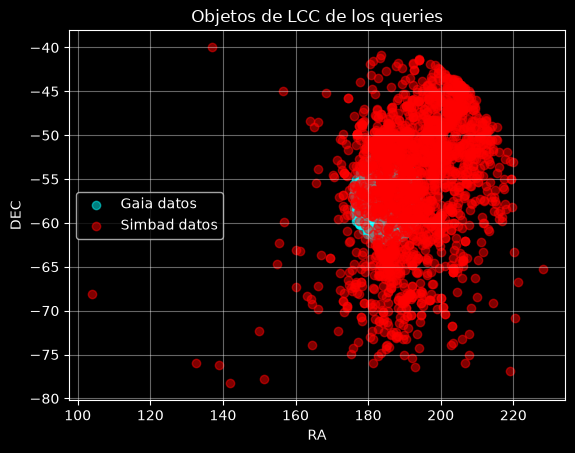

In [154]:
plt.scatter(result_LCC['ra'], result_LCC['dec'],
            color='cyan', alpha=0.5, label='Gaia datos')
plt.scatter(sub_LCC["RA_d"], sub_LCC['DEC_d'],
            color='red', alpha=0.5, label='Simbad datos')
plt.title("Objetos de LCC de los queries")
plt.legend(loc='best')
plt.xlabel("RA")
plt.ylabel("DEC")
plt.grid(alpha=0.4)
plt.show()

Aquí entonces nos interesa ver es la dinámica del cúmulo, hacia donde se mueve, por lo que vamos a plotear las componentes de movimiento propio.

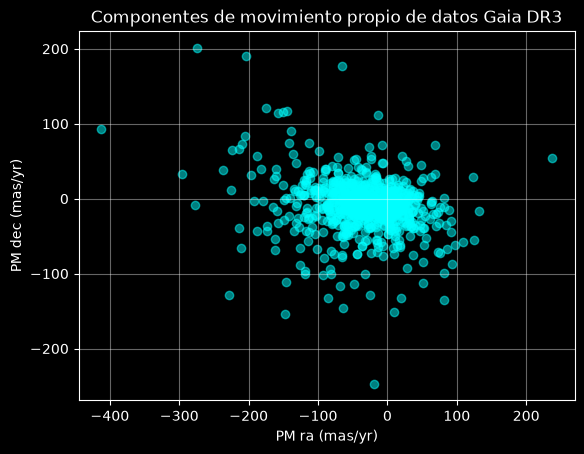

In [155]:
plt.scatter(result_LCC['pmra'], result_LCC['pmdec'], color='cyan', alpha=0.5)
plt.title("Componentes de movimiento propio de datos Gaia DR3")
plt.xlabel("PM ra (mas/yr)")
plt.ylabel("PM dec (mas/yr)")
plt.grid(alpha=0.4)
plt.show()

Empero, lo anterior no es suficiente, requerimos de la velocidad radial para determinar las componentes cartesianas de la velocidad de cada estrella. Revisemos al columna de velocidades radiales vs las componentes de movimiento propio.

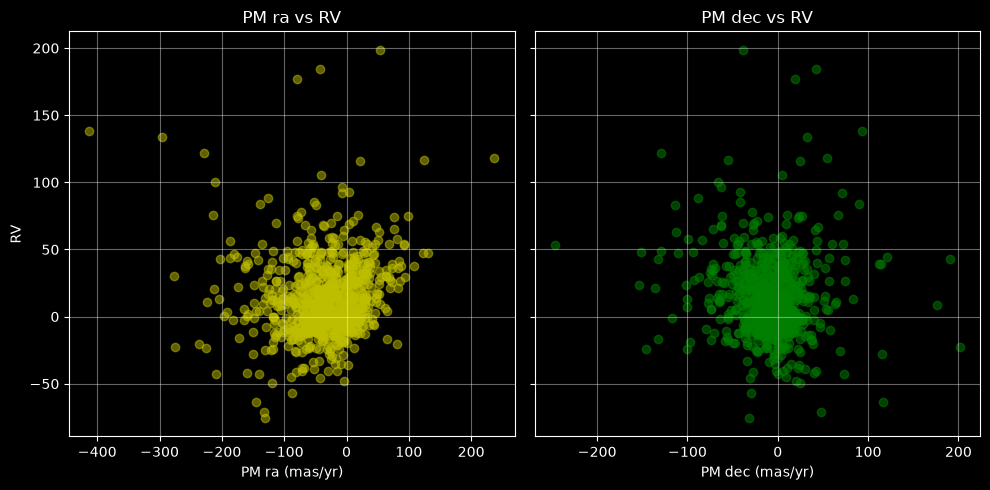

In [156]:
figura1, axs1 = plt.subplots(1, 2, figsize=(10,5), sharey=True)

axs1[0].scatter(result_LCC['pmra'], result_LCC['radial_velocity'], color='y',
                alpha=0.5)
axs1[0].set_title("PM ra vs RV")
axs1[0].set_xlabel("PM ra (mas/yr)")
axs1[0].set_ylabel("RV")
axs1[0].grid(alpha=0.4)

axs1[1].scatter(result_LCC['pmdec'], result_LCC['radial_velocity'], color='g',
                alpha=0.5)
axs1[1].set_title("PM dec vs RV")
axs1[1].set_xlabel("PM dec (mas/yr)")
axs1[1].grid(alpha=0.4)

plt.tight_layout()
plt.show()

Veamos los paralajes, aunque sabemos que los solicitamos en un rango específico, nos sirve para el análisis.

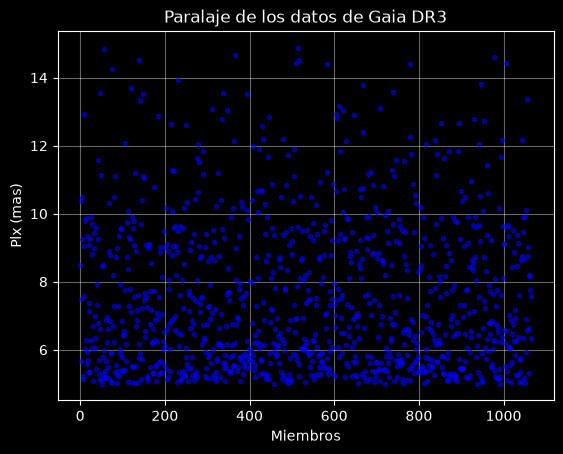

In [157]:
plt.plot(result_LCC['parallax'], 'b.', alpha=0.5)
plt.title("Paralaje de los datos de Gaia DR3")
plt.xlabel("Miembros")
plt.ylabel("Plx (mas)")
plt.grid(alpha=0.4)
plt.show()

## **Filtrado por errores**

Para que nuestro futuro modelo de Gaussian Mixtures no sufra explicando datos crudos con posibles errores instrumentales vamos a hacer dos filtros principales:

1. Error absoluto de movimiento propio: definiremos una tolerancia máxima para el error absoluto de ambas componentes.

2. Error relativo de paralaje: en los papers e investigaciones de éste se acostumbra a tener una $S/N > 10$, con tal de que no tengamos datos

### **1) Filtro de error relativo del paralaje**

Aquí tendremos en cuenta la $S/N$ que tiene esta medición, ya que no queremos datos con una baja $S/N$. Como Lower Centaurus-Crux está relativamente cercano al Sistema Solar podemos definir el criterio de aceptación como:

$$S/N > 10$$

Si es así aceptamos el dato, de lo contrario lo rechazamos, veamos un histograma de estos datos.

In [159]:
len(result_LCC)

1066

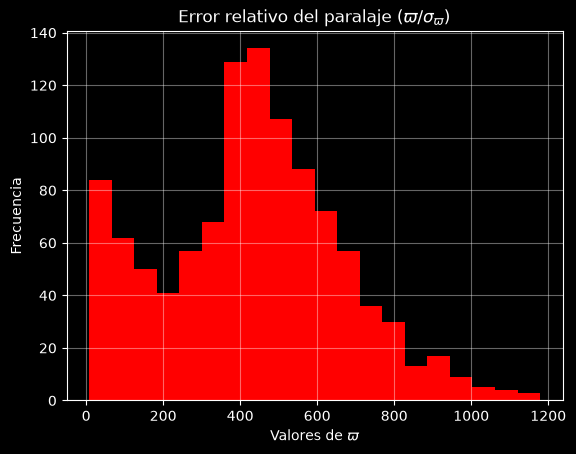

In [160]:
plt.hist(result_LCC['plx_oerr'], bins='auto', color='red')
plt.title(r"Error relativo del paralaje $(\varpi / \sigma_\varpi)$")
plt.xlabel(r'Valores de $\varpi$')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.4)
plt.show()

In [161]:
mask_LCC_plx = result_LCC['plx_oerr'] > 10

filtro_1_LCC = result_LCC[mask_LCC_plx]
print(len(result_LCC), len(filtro_1_LCC))

1066 1060


### **2) Incertidumbres de movimientos propios**

Ahora vamos a revisar con lupa los movimientos propios.

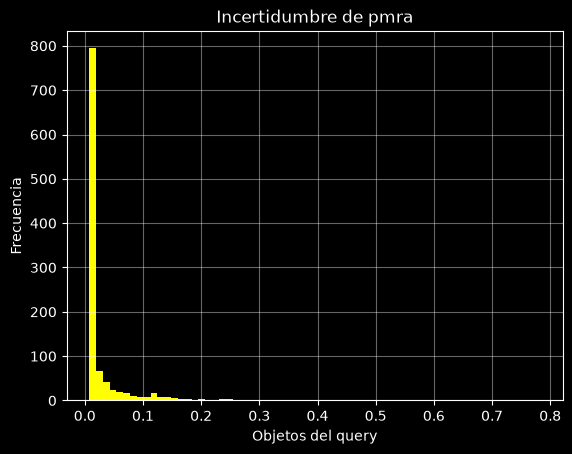

In [162]:
plt.hist(result_LCC['pmra_error'], bins='auto', color='yellow')
plt.title("Incertidumbre de pmra")
plt.xlabel('Objetos del query')
plt.ylabel('Frecuencia')
plt.grid(alpha=0.4)
plt.show()

El filtro para las componentes de movimiento propio consiste en restringir aquellas estrellas cuyos errores absolutos superen cierta tolerancia. Aquí tenemos componentes de movimiento propio en mas, por lo que son movimiento pequeñísimos. Restringimos a que el error absoluto sea menor que $0.3$, ya que estas componentes tiene

In [163]:
mask_pm_LCC = (filtro_1_LCC['pmra_error'] < 0.05) & (filtro_1_LCC['pmdec_error'] < 0.05)

In [164]:
filtro_2_LCC = filtro_1_LCC[mask_pm_LCC]
len(filtro_2_LCC)

912

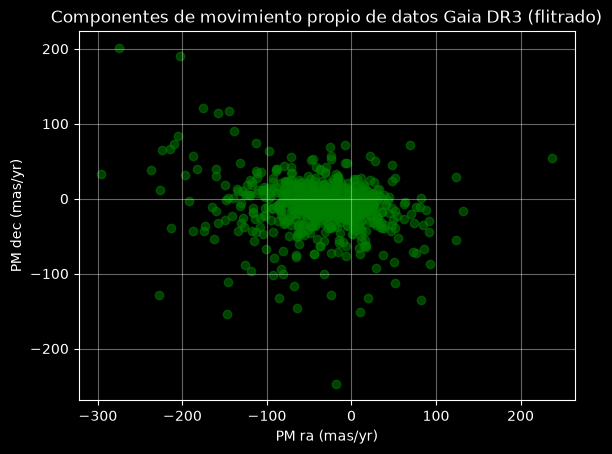

In [165]:
plt.scatter(filtro_2_LCC['pmra'], filtro_2_LCC['pmdec'], color='green', alpha=0.5)
plt.title("Componentes de movimiento propio de datos Gaia DR3 (flitrado)")
plt.xlabel("PM ra (mas/yr)")
plt.ylabel("PM dec (mas/yr)")
plt.grid(alpha=0.4)
plt.show()

Lo que queremos conocer con nuestros datos es la representación cartesiana en el espacio. Hay que aclarar que el origen de nuestro sistema de referencia es la misma Tierra, aquí contamos con las componentes en coordenadas esféricas para cada estrella, es decir, con sus coordenadas ecuatoriales en el marco ICRS.

Vamos a utilizar los elementos de `SkyCoord` de `astropy` para representar de forma cartesiana las estrellas en esa región del cielo.

## **Prueba con un dato random**

Esto es simplemente una visualización de la creación de las componentes cartesiandas de un objeto random.

In [166]:
dato_random = result_LCC['ra',
                         'dec',
                         'parallax',
                         'pmra',
                         'pmdec',
                         'radial_velocity'][0]
dato_random

ra,dec,parallax,pmra,pmdec,radial_velocity
deg,deg,mas,mas / yr,mas / yr,km / s
float64,float64,float64,float64,float64,float32
192.74262865215735,-58.17691145027575,8.482504067796272,0.919739568814625,2.6647006543768526,-8.573328


In [25]:
ra_rd = dato_random['ra'] * u.deg
dec_rd = dato_random['dec'] * u.deg
plx_rd = dato_random['parallax'] * u.mas
pmra_rd = dato_random['pmra'] * (u.mas / u.yr)
pmdec_rd = dato_random['pmdec'] * (u.mas / u.yr)
rv_rd = dato_random['radial_velocity'] * u.km / u.s
print(rv_rd)

# Distancia:
dist_rd = plx_rd.to(u.pc, equivalencies=u.parallax())
dist_rd

-16.494718551635742 km / s


<Quantity 116.08222929 pc>

Primero debemos crear el objeto tipo `SkyCoord` que contendrá los datos que necesitamos del objeto.

In [26]:
rd_skycc = SkyCoord(
    ra=ra_rd,
    dec=dec_rd,
    distance=dist_rd,
    pm_ra_cosdec=pmra_rd,
    pm_dec=pmdec_rd,
    radial_velocity=rv_rd
)

rd_skycc

<SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, pc)
    (172.0487676, -44.56111368, 116.08222929)
 (pm_ra_cosdec, pm_dec, radial_velocity) in (mas / yr, mas / yr, km / s)
    (-82.25775837, 29.82222507, -16.494719)>

Finalmente podemos obtener la representación cartesiana respecto al marco de referencia de La Tierra con la función `CartesianRepresentation`.

In [27]:
# Aquí hacemos la representación cartesiana y la convertimos a un array:
cartesian_rd = rd_skycc.represent_as(CartesianRepresentation)

cartesian_xyz = cartesian_rd.xyz.value
print("Componentes de posición cartesianas en parsecs")
print(cartesian_xyz)

print("Componentes de velocidad cartesianas en mas * pc / (rad yr)")
cartesian_vs = cartesian_rd.differentials['s'].d_xyz.to(u.pc / u.Myr).value
print(cartesian_vs)

Componentes de posición cartesianas en parsecs
[-81.91372117  11.44113283 -81.45137642]
Componentes de velocidad cartesianas en mas * pc / (rad yr)
[ 6.64444519 45.81455543 23.794943  ]


In [28]:
np.concatenate((cartesian_xyz, cartesian_vs))

array([-81.91372117,  11.44113283, -81.45137642,   6.64444519,
        45.81455543,  23.794943  ])

## **Componentes cartesianas de Lower Centaurus-Crux:**

Aquí vamos a crear una función iterativa que devuelva las componentes cartesianas de todos los miembros del grupo estelar de LCC.

In [29]:
def cartesian_coordinates(resultado):
  dato_random = resultado['ra',
                         'dec',
                         'parallax',
                         'pmra',
                         'pmdec',
                         'radial_velocity']

  # Vamos a obtener los datos de movimiento propio, coordenadas
  # y además la velocidad radial:
  ra_rd = dato_random['ra'] * u.deg
  dec_rd = dato_random['dec'] * u.deg
  plx_rd = dato_random['parallax'] * u.mas
  pmra_rd = dato_random['pmra'] * (u.mas / u.yr)
  pmdec_rd = dato_random['pmdec'] * (u.mas / u.yr)
  rv_rd = dato_random['radial_velocity'] * u.km / u.s

  # Debemos obtener la distancia:
  dist_rd = plx_rd.to(u.pc, equivalencies=u.parallax())

  # Creamos un objeto skycoord:
  rd_skycc = SkyCoord(
    ra=ra_rd,
    dec=dec_rd,
    distance=dist_rd,
    pm_ra_cosdec=pmra_rd,
    pm_dec=pmdec_rd,
    radial_velocity=rv_rd
  )

  # Obtenemos la representación cartesiana
  cartesian_rd = rd_skycc.represent_as(CartesianRepresentation)

  # Coordenadas xyz:
  cartesian_xyz = cartesian_rd.xyz.value
  # Velocidades:
  cartesian_vs = cartesian_rd.differentials['s'].d_xyz.to(u.pc / u.Myr).value

  # Hacemos un súper vector:
  cartesian_all = np.concatenate((cartesian_xyz, cartesian_vs))

  return cartesian_all

Vamos a aplicar la función anterior de `cartesian_coordinates` a los datos que sobrevivieron nuestros filtros principales, así vamos a encontrar las componentes cartesianas de todos los miembros del grupo.

In [30]:
cartesian_LCC = np.zeros((len(filtro_2_LCC), 6))

for i, cp in enumerate(filtro_2_LCC):
  cartesian_LCC[i] = cartesian_coordinates(cp)

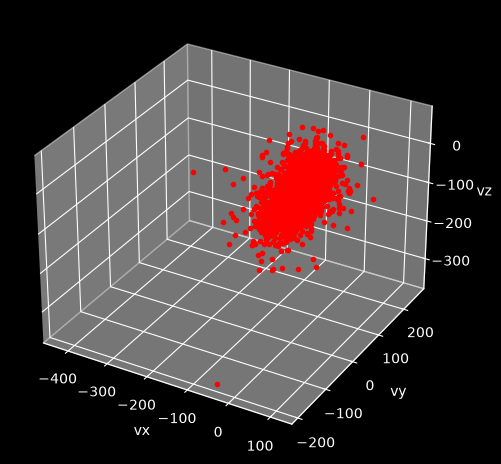

In [31]:
LCC_vs = plt.figure().add_subplot(projection='3d')

LCC_vs.plot(
    cartesian_LCC[:,3], cartesian_LCC[:,4], cartesian_LCC[:,5],
    'r.'
    )
LCC_vs.set_xlabel('vx')
LCC_vs.set_ylabel('vy')
LCC_vs.set_zlabel('vz')

plt.tight_layout()
plt.show()

Vamos a hacer un quiver tridimensional para ver mejor nuestros vectores de velocidad de Lower Centaurus-Crux association:

In [32]:
subset = np.random.choice(len(cartesian_LCC), size=200, replace=False)

# Elejimos aleatoriamente las posiciones
x_subset = cartesian_LCC[:,0][subset]
y_subset = cartesian_LCC[:,1][subset]
z_subset = cartesian_LCC[:,2][subset]

# Así mismo con las velocidades:
vx_subset = cartesian_LCC[:,3][subset]
vy_subset = cartesian_LCC[:,4][subset]
vz_subset = cartesian_LCC[:,5][subset]

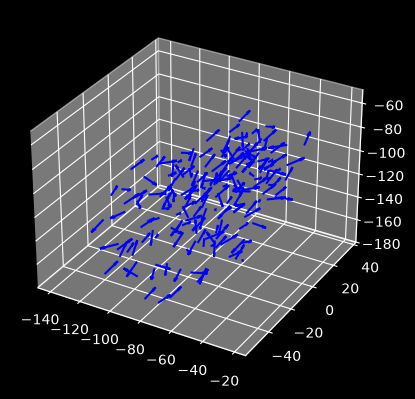

In [33]:
ax = plt.figure().add_subplot(projection='3d')

# Hacemos la maya con las posiciones:

ax.quiver(x_subset, y_subset, z_subset,
          vx_subset, vy_subset, vz_subset,
          length=10.0, normalize=True, color='blue')

## **Gaussian Mixtures**

In [34]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

Aquí vamos a iniciar todo escalando a normales estándar para poder aplicar el método de Gaussian Mixtures, ya que queremos manejar los datos bien. El proceso de escalado busca normalizar la variable $X$ en cuestión a una variable normal estándar $Z$:

$$Z = \frac{X - \mu}{S_{X}}$$

In [35]:
#scaler = StandardScaler()
#Xs_LCC_scaled = scaler.fit_transform(cartesian_LCC)

In [36]:
#Xs_LCC_scaled

Creamos el modelo de Gaussian Mixture entrenando el sistema con los datos normalizados.

In [145]:
gmm_LCC = GaussianMixture(
    n_components=2,
    covariance_type='full',
    random_state=42
)

# Vamos a acomodar (fitear) los datos:
gmm_LCC.fit(cartesian_LCC)
# Aquí calculamos la pertenencia a un cluster
labels = gmm_LCC.predict(cartesian_LCC)
means = gmm_LCC.means_
pesos = gmm_LCC.weights_

print(means)
print(pesos)
print(labels.shape)

[[ -61.10402716   -7.24347463  -94.64995034   -1.70801985   20.60739689
   -10.01328767]
 [ -89.49884794   -6.56781549 -141.32901165   -4.551116     26.2476696
   -14.05958058]]
[0.43143411 0.56856589]
(7609,)


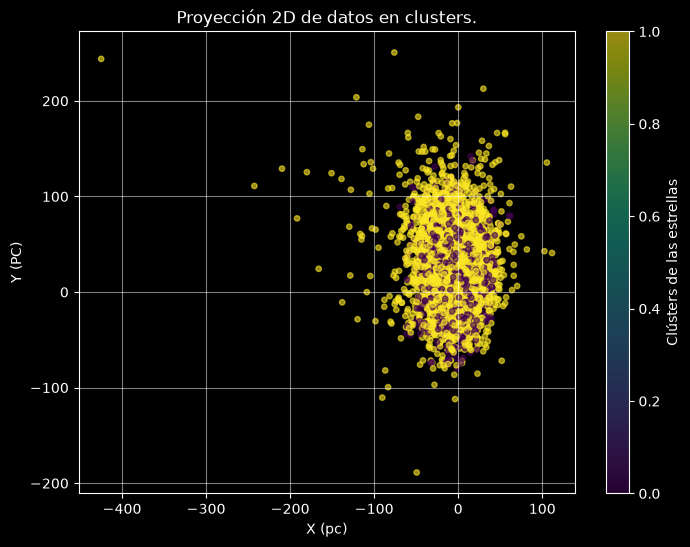

In [38]:
plt.figure(figsize=(8,6))

plt.scatter(
    cartesian_LCC[:,3],
    cartesian_LCC[:,4],
    c=labels,
    cmap='viridis',
    s=15,
    alpha=0.6
)

plt.xlabel('X (pc)')
plt.ylabel('Y (PC)')
plt.title('Proyección 2D de datos en clusters.')
plt.grid(alpha=0.5)
plt.colorbar(label='Clústers de las estrellas')
plt.show()

Vamos a analizar los gráficos de dispersión de cada una de las variables con un gráfico de pairplot de `seaborn`.

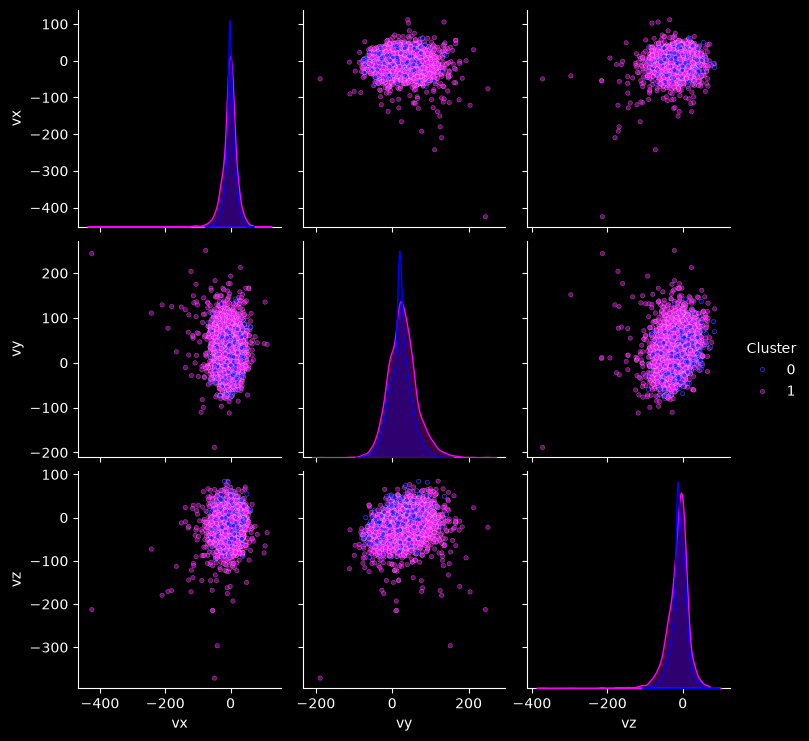

In [39]:
df_cartesianLCC = pd.DataFrame(
    cartesian_LCC[:,3:],
    columns=['vx', 'vy', 'vz']
)

# Añadimos la columna 'Cluster' con las etiquetas obtenidas del modelo GMM
df_cartesianLCC['Cluster'] = labels

# Definimos los colores de los clusters:
LCC_colors = {
    0: 'blue',
    1: 'magenta'
}

# El pair plot va a recibir los datos y los va plotear en forma de una matriz.
sns.pairplot(
    df_cartesianLCC,
    hue='Cluster',
    diag_kind='kde',
    palette=LCC_colors,
    vars=['vx', 'vy', 'vz'],
    plot_kws={'alpha': 0.5, 's': 10}
)

plt.show()

Veamos la pertenencia a alguno de los dos clusters:

In [127]:
LCC_C1, LCC_C2 = 0, 1

mask_c1 = (labels == LCC_C1)
mask_c2 = (labels == LCC_C2)

probabilidades_LCC = gmm_LCC.predict_proba(cartesian_LCC)

# Aquí las que pertenecen al cluster 1
mask_1 = (probabilidades_LCC[:,1] >= 0.9)
# Estas pertenecen al cluster 0
mask_0 = (probabilidades_LCC[:,1] <= 0.1)

LCC_gues0 = cartesian_LCC[mask_1]
# Cambiemos momentáneamente al cluster 0
LCC_guess = cartesian_LCC[mask_0]

In [128]:
cartesian_LCC.shape

(7609, 6)

In [129]:
print(LCC_gues0.shape)
print(LCC_guess.shape)

(3300, 6)
(2386, 6)


In [130]:
import plotly.io as pio

# Forzar renderizado estático para que no dependa de WebGL en el notebook
pio.renderers.default = "browser"

# Y luego ejecutas tu fig.show() normal

Aquí puede visualizarse el cluster 1

In [131]:
ms = 4000
xs, ys, zs = LCC_guess[:ms, 0], LCC_guess[:ms, 1], LCC_guess[:ms, 3]
vxs, vys, vzs = LCC_guess[:ms, 3], LCC_guess[:ms, 4], LCC_guess[:ms, 5]

fig = go.Figure(data=[go.Cone(
    x=xs, y=ys, z=zs, 
    u=vxs, v=vys, w=vzs,
    sizemode='scaled',
    sizeref=6.0,
    colorscale='magenta',
    name='Clúster 1'
),
    go.Cone(
        x=LCC_gues0[:,0], y=LCC_gues0[:,1], z=LCC_gues0[:,2], 
        u=LCC_gues0[:,3], v=LCC_gues0[:,4], w=LCC_gues0[:,5],
        sizemode='scaled',
        sizeref=20.0,
        colorscale='greens',
        name='Cluster 0'
    )
])

fig.update_layout(title='Campo de velocidades de un cluster',
                  scene=dict(
                      xaxis_title='(X )pc',
                      yaxis_title='Y (pc)',
                      zaxis_title='Z (pc)'
                  )
                  )

fig.show()

## **Estimación de la edad cinemática**

Aquí vamos a recurrir a la aproximación más sencilla y es mirar cuando las estrellas se cruzaron. Usando relatividad galileana podemos usar las eucaciones de movimiento del MRU:

$$x_{i,\text{pasado}}(t) = x_{i, \text{hoy}} + v_i \cdot t$$

Aquí creamos el esqueleto de la función para todas las posiciones:

In [132]:
ts = np.linspace(0, -10, 500)

Aquí calculamos las posiciones cartesiana en base a las ecuaciones del Movimiento Rectilíneo Uniforme, para ello usamos las estrellas que pertenecen al cluster 1.

In [133]:
posiciones = LCC_guess[:,:3]
velocidades = LCC_guess[:,3:]
distancias = np.zeros((len(ts), len(posiciones)))

promedios = np.zeros((len(ts), 3))

pos_pasado = np.zeros((len(ts), len(posiciones), 3))

for i, t in enumerate(ts):
    # Calculamos las posiciones hacia atrás en el tiempo.
    pos_pasado[i] = posiciones + velocidades * t

    # Calculamos el centroide de cada tiempo:
    promedios[i] = np.mean(pos_pasado[i], axis=0) 

    # Calculamos las normas de cada vector de posición de las estrellas
    # en un momento del tiempo.
    distancias[i] = np.linalg.norm(pos_pasado[i] - promedios[i], axis=1)

# Calculamos la desviación estándar de las normas para luego
# comparar cuál es la mínima.
stds = np.std(distancias, axis=1)

print(distancias.shape)

(500, 2386)


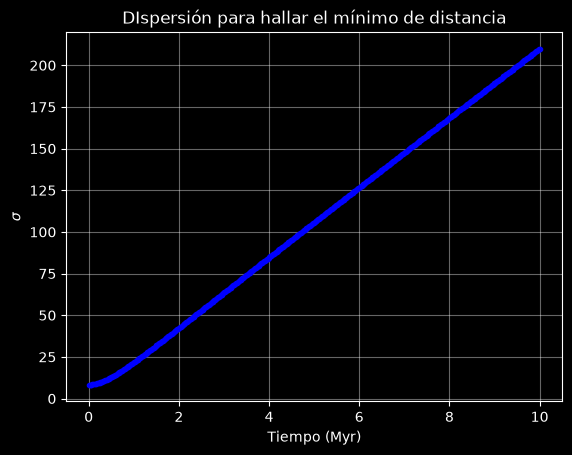

In [134]:
plt.plot(-ts, stds, 'b.')
plt.title('DIspersión para hallar el mínimo de distancia')
plt.xlabel('Tiempo (Myr)')
plt.ylabel(r'$\sigma$')
plt.grid(alpha=0.4)
plt.show()

In [135]:
pos_pasado

array([[[ -81.91372117,   11.44113283,  -81.45137642],
        [ -54.39802161,   -5.82278721,  -52.95860267],
        [ -86.75975786,  -11.03946645,  -82.22789295],
        ...,
        [ -62.36779832,   12.86040151, -104.60868364],
        [ -63.37073736,   21.05758277, -102.017327  ],
        [ -43.96913284,   17.18379477,  -68.45858811]],

       [[ -82.04687638,   10.52300546,  -81.92822899],
        [ -54.51411554,   -6.46080769,  -52.88849281],
        [ -87.09101391,  -11.98012819,  -82.5362475 ],
        ...,
        [ -62.24948102,   12.09882324, -104.74336326],
        [ -63.3206527 ,   20.24768532, -102.30560545],
        [ -44.38730911,   15.67419198,  -68.01696845]],

       [[ -82.18003159,    9.6048781 ,  -82.40508155],
        [ -54.63020946,   -7.09882817,  -52.81838296],
        [ -87.42226996,  -12.92078993,  -82.84460205],
        ...,
        [ -62.13116372,   11.33724496, -104.87804288],
        [ -63.27056804,   19.43778786, -102.5938839 ],
        [ -44.80548539

In [136]:
np.linalg.norm(pos_pasado[0] - promedios[0], axis=1)

array([32.57654315, 33.21251155, 31.59459735, ..., 28.12888576,
       33.36682311, 32.31842065], shape=(2386,))

Aquí podemos pedir las componentes cartesianas de cada momento de la siguiente manera:

`pos_pasado[ti,vi,xi]`

Donde la componente $t_i$ es el i-ésimo momento en el tiempo, la componente $v_i$ es del i-ésimo vector de posición, y la componente $x_i$ es la i-ésima componente cartesiana o de posición.

Aquí para plotear las estrellas debemos tener: todas las componentes temporales en la que la estrella se ha movido, la j-ésima estrella en cuestión y la k-ésima componente cartesiana de posición:

`pos_pasado[:,vj,xk]`

In [137]:
x0 = pos_pasado[:,0,0]
y0 = pos_pasado[:,0,1]
z0 = pos_pasado[:,0,2]

In [138]:
np.mean(pos_pasado[0,:,:], axis=0)

array([-55.63663481,  -7.23962776, -86.1177541 ])

In [139]:
prom00 = np.mean(pos_pasado[-1,:,:], axis=0)
prom00

array([ -40.04924111, -204.84720864,   12.76148644])

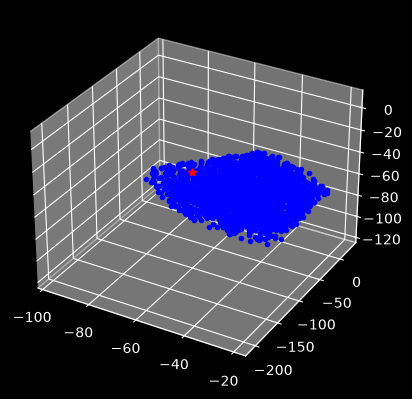

In [140]:
ax00 = plt.figure().add_subplot(projection='3d')

ax00.plot(
    pos_pasado[0,:,0], pos_pasado[0,:,1], pos_pasado[0,:,2],
    'b.'
)
ax00.plot(
    prom00[0], prom00[1], prom00[2],
    'r*'
)

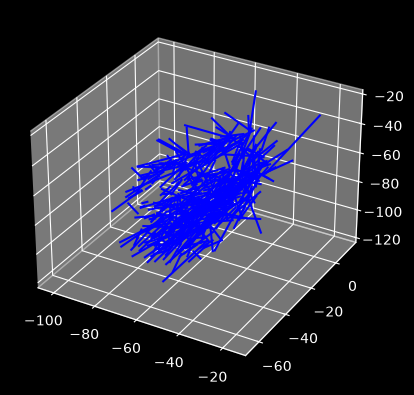

In [141]:
ax_LCC = plt.figure().add_subplot(projection='3d')

for i in range(len(pos_pasado)):
    ax_LCC.plot(
        pos_pasado[:20,i,0],
        pos_pasado[:20,i,1],
        pos_pasado[:20,i,2] ,
        color='blue'
)